<div align="center">

# 🚗 Used Cars Price Analysis


![Python](https://img.shields.io/badge/Python-3.10+-blue?logo=python&logoColor=white)
![Pandas](https://img.shields.io/badge/Pandas-Data%20Analysis-150458?logo=pandas)
![Plotly](https://img.shields.io/badge/Plotly-Interactive-3F4F75?logo=plotly)
![Scikit-learn](https://img.shields.io/badge/scikit--learn-ML-F7931E?logo=scikitlearn&logoColor=white)

**An end-to-end data analysis and price prediction project on the US used car market**

</div>

<div align="center">
    <img src="https://images.unsplash.com/photo-1492144534655-ae79c964c9d7"
         width="850"
         alt="Luxury Car"/>
</div>

---

## 📌 Project Overview

This project analyzes **5,500 used cars** listed in the US market. The goal is to understand what drives a car's selling price and to build a machine learning model that predicts it.

## 🎯 Business Questions

1. Which factors influence the selling price the most?
2. How fast do cars lose value with age (depreciation)?
3. How much does an accident history reduce the price?
4. Do Electric and Hybrid cars hold their value better?
5. Do color or location have a real effect on price?
6. How accurately can we predict the selling price?

## 📊 Dataset Description

**Size:** 5,500 rows × 18 columns

| Group | Columns | Description |
|---|---|---|
| Identity | `Make`, `Model`, `Year`, `Body_Type`, `Color` | Brand, model name, manufacturing year, body style, color |
| Specs | `Fuel_Type`, `Transmission`, `Engine_Size`, `Horsepower`, `Torque`, `Drivetrain`, `Fuel_Efficiency` | Technical and performance features |
| Condition | `Mileage`, `Owners`, `Accident_History`, `Service_History` | Usage and maintenance history |
| Market | `Location`, `Selling_Price` | US state and the **target variable** (USD) |

**Key data challenges:**
- ~15% missing values across 9 columns (~76% of rows have at least one missing value)
- `Engine_Size = 0` for Electric cars (valid, not an error)
- `Fuel_Efficiency` for Electric cars is on a different scale (MPGe)
- `Selling_Price` is right-skewed → log transformation needed

## 🛠️ Tech Stack

| Purpose | Libraries |
|---|---|
| Data manipulation | `pandas`, `numpy` |
| Static visualization | `matplotlib`, `seaborn` |
| Interactive visualization | `plotly`, `altair` |
| Missing values analysis | `missingno` |
| Machine learning | `scikit-learn`, `xgboost` |
| Model explainability | `shap` |

## 🗺️ Notebook Roadmap

1. **Setup & Data Audit**
2. **Data Cleaning**: missing values, outliers, data types
3. **Exploratory Data Analysis (EDA)**
4. **Feature Engineering**
5. **Modeling & Evaluation**
6. **Insights & Conclusions**

---

**Import libraries**

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="deep", font_scale=1.1)
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)

**Load + Overview**

In [17]:
df= pd.read_csv(r"D:\Codex Ai Course\Codex Training Projects\Python Project\automobile_dataset.csv")
print("Shape:",df.shape)
print("Duplicates:", df.duplicated().sum())
df.head()

Shape: (5500, 18)
Duplicates: 0


,Make,Model,Year,Fuel_Type,Transmission,Engine_Size,Mileage,Horsepower,Torque,Owners,Accident_History,Service_History,Color,Body_Type,Drivetrain,Fuel_Efficiency,Location,Selling_Price
0,Mercedes-Benz,GLE,2024,Petrol,Automatic,2.3,100,186.0,196.0,1,0.0,NaN,Silver,SUV,AWD,30.0,IL,64140
1,Hyundai,Tucson,2008,Petrol,Automatic,2.3,387035,189.0,190.0,4,0.0,NaN,Blue,SUV,FWD,35.0,FL,500
2,Volkswagen,Golf,2021,Hybrid,NaN,1.9,46054,158.0,153.0,1,0.0,Partial Service,Gray,Hatchback,AWD,43.0,NY,16429
3,Chevrolet,Tahoe,2005,Petrol,NaN,2.2,141302,169.0,165.0,5,1.0,No Service,Blue,SUV,AWD,NaN,FL,2199
4,Toyota,Camry,2022,Petrol,Automatic,1.9,32813,149.0,141.0,1,0.0,Full Service,Brown,Sedan,FWD,38.0,CA,21792


In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Make              5500 non-null   str    
 1   Model             5500 non-null   str    
 2   Year              5500 non-null   int64  
 3   Fuel_Type         5500 non-null   str    
 4   Transmission      4673 non-null   str    
 5   Engine_Size       4656 non-null   float64
 6   Mileage           5500 non-null   int64  
 7   Horsepower        4700 non-null   float64
 8   Torque            4701 non-null   float64
 9   Owners            5500 non-null   int64  
 10  Accident_History  4688 non-null   float64
 11  Service_History   4645 non-null   str    
 12  Color             4697 non-null   str    
 13  Body_Type         5500 non-null   str    
 14  Drivetrain        5500 non-null   str    
 15  Fuel_Efficiency   4706 non-null   float64
 16  Location          4718 non-null   str    
 17  Sellin

In [19]:
df.columns

Index(['Make', 'Model', 'Year', 'Fuel_Type', 'Transmission', 'Engine_Size',
       'Mileage', 'Horsepower', 'Torque', 'Owners', 'Accident_History',
       'Service_History', 'Color', 'Body_Type', 'Drivetrain',
       'Fuel_Efficiency', 'Location', 'Selling_Price'],
      dtype='str')

**Missing values**

In [20]:
df.isna().sum()

Make                  0
Model                 0
Year                  0
Fuel_Type             0
Transmission        827
Engine_Size         844
Mileage               0
Horsepower          800
Torque              799
Owners                0
Accident_History    812
Service_History     855
Color               803
Body_Type             0
Drivetrain            0
Fuel_Efficiency     794
Location            782
Selling_Price         0
dtype: int64

In [21]:
missing=(df.isna().mean()*100).round(2)
missing

Make                 0.00
Model                0.00
Year                 0.00
Fuel_Type            0.00
Transmission        15.04
Engine_Size         15.35
Mileage              0.00
Horsepower          14.55
Torque              14.53
Owners               0.00
Accident_History    14.76
Service_History     15.55
Color               14.60
Body_Type            0.00
Drivetrain           0.00
Fuel_Efficiency     14.44
Location            14.22
Selling_Price        0.00
dtype: float64

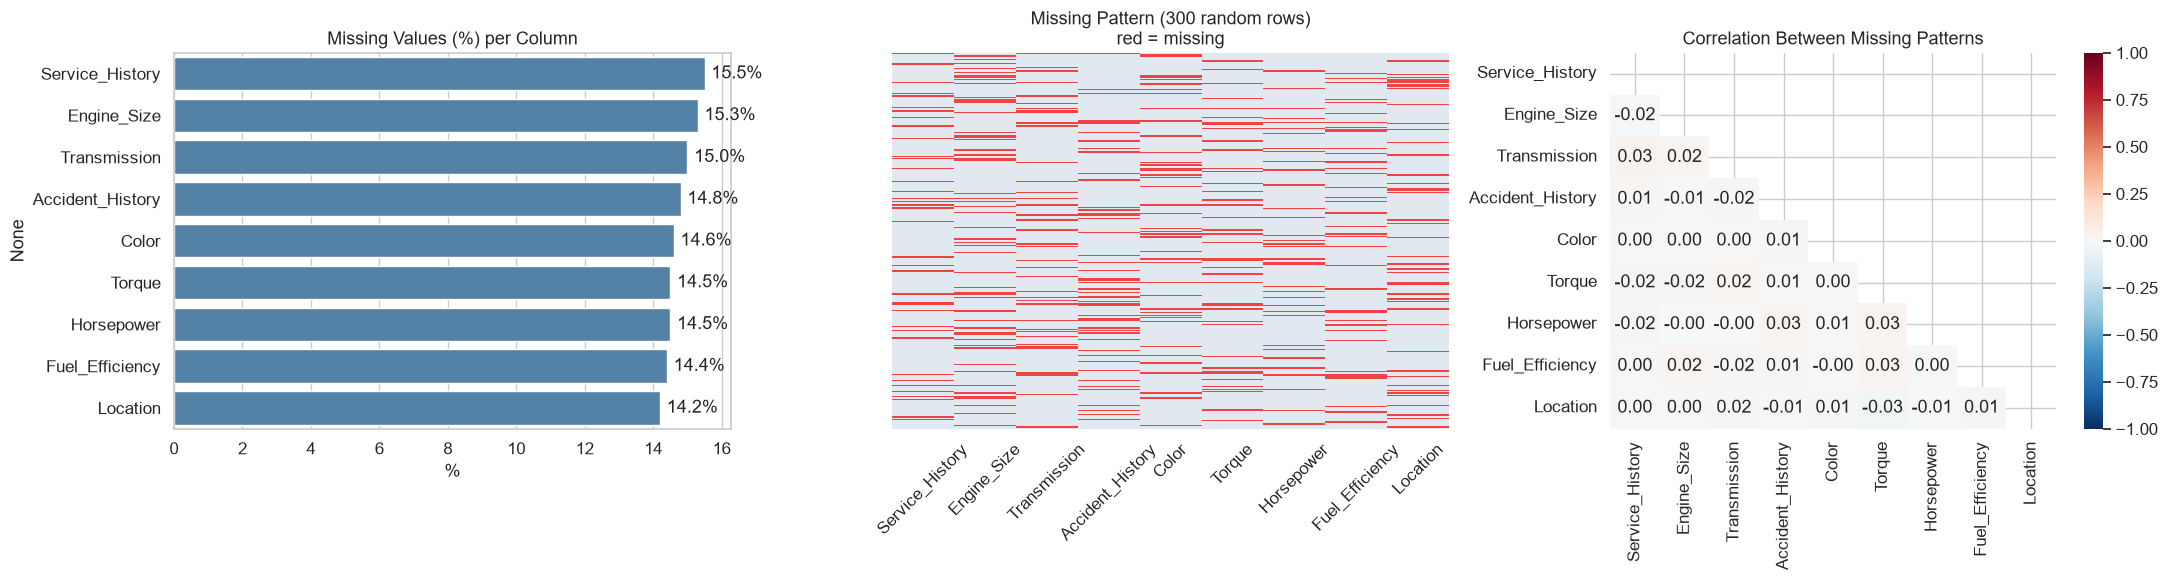

In [22]:
# Percentage of missing values per column
missing_pct = (df.isna().mean() * 100).round(1)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)
miss_cols = missing_pct.index.tolist()

fig, ax = plt.subplots(1, 3, figsize=(22, 6))

# 1) Bar chart: missing % per column
sns.barplot(x=missing_pct.values, y=missing_pct.index, ax=ax[0], color="steelblue")
ax[0].set_title("Missing Values (%) per Column")
ax[0].set_xlabel("%")
for i, v in enumerate(missing_pct.values):
    ax[0].text(v + 0.2, i, f"{v}%", va="center")

# 2) Missing pattern on a random sample of rows (red = missing)
sample = df[miss_cols].sample(300, random_state=42).isna()
sns.heatmap(sample, cbar=False, yticklabels=False,
            cmap=["#e2e8f0", "#ef4444"], ax=ax[1])
ax[1].set_title("Missing Pattern (300 random rows)\nred = missing")
ax[1].tick_params(axis="x", rotation=45)

# 3) Correlation between missing indicators
corr = df[miss_cols].isna().astype(int).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f",
            cmap="RdBu_r", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Correlation Between Missing Patterns")

plt.tight_layout()
plt.show()

In [23]:
# Missing rate per Fuel_Type: similar rates => not tied to car type
cols = ["Engine_Size", "Horsepower", "Transmission", "Fuel_Efficiency"]
df.groupby("Fuel_Type")[cols].apply(lambda g: g.isna().mean().round(3))

,Engine_Size,Horsepower,Transmission,Fuel_Efficiency
Fuel_Type,,,,
Diesel,0.136,0.136,0.165,0.149
Electric,0.124,0.172,0.131,0.117
Hybrid,0.173,0.177,0.162,0.123
Petrol,0.154,0.142,0.148,0.147


In [24]:
print(df.groupby("Make")["Model"].nunique())
print("Price skew:", round(df["Selling_Price"].skew(), 2))
print("Log price skew:", round(np.log1p(df["Selling_Price"]).skew(), 2))

Make
Audi             4
BMW              4
Chevrolet        4
Ford             4
Honda            4
Hyundai          4
Mercedes-Benz    4
Nissan           4
Toyota           4
Volkswagen       4
Name: Model, dtype: int64
Price skew: 1.34
Log price skew: -0.49


## ✅ Phase 1 Summary

- **Missing values** are random (max correlation between missing patterns = 0.033), spread evenly across brands and fuel types.
- No rows are severely incomplete, so **no row deletion** is needed.
- Each `Make` has exactly **4 models**, so `Model` can be used to impute technical specs accurately.
- `Selling_Price` is right-skewed (1.34) → **log transform** will be used.
- Early signals: `Year` (+0.80) and `Mileage` (-0.68) are the strongest price drivers.

# **Phase 2: Data Cleaning**

**Handling Missing Values**

In [25]:
df_clean = df.copy()

# Accident: unknown history is NOT the same as "no accident"
df_clean["Accident_History"] = (df_clean["Accident_History"]
                                .map({0.0: "No", 1.0: "Yes"})
                                .fillna("Unknown"))

# Categorical columns with no logical default -> "Unknown"
for col in ["Service_History", "Color", "Location"]:
    df_clean[col] = df_clean[col].fillna("Unknown")

# Transmission: ~76% automatic in every model, no model-level signal -> mode
df_clean["Transmission"] = df_clean["Transmission"].fillna(df_clean["Transmission"].mode()[0])

df_clean.head()

,Make,Model,Year,Fuel_Type,Transmission,Engine_Size,Mileage,Horsepower,Torque,Owners,Accident_History,Service_History,Color,Body_Type,Drivetrain,Fuel_Efficiency,Location,Selling_Price
0,Mercedes-Benz,GLE,2024,Petrol,Automatic,2.3,100,186.0,196.0,1,No,Unknown,Silver,SUV,AWD,30.0,IL,64140
1,Hyundai,Tucson,2008,Petrol,Automatic,2.3,387035,189.0,190.0,4,No,Unknown,Blue,SUV,FWD,35.0,FL,500
2,Volkswagen,Golf,2021,Hybrid,Automatic,1.9,46054,158.0,153.0,1,No,Partial Service,Gray,Hatchback,AWD,43.0,NY,16429
3,Chevrolet,Tahoe,2005,Petrol,Automatic,2.2,141302,169.0,165.0,5,Yes,No Service,Blue,SUV,AWD,NaN,FL,2199
4,Toyota,Camry,2022,Petrol,Automatic,1.9,32813,149.0,141.0,1,No,Full Service,Brown,Sedan,FWD,38.0,CA,21792


In [26]:
df_clean.isna().sum()

Make                  0
Model                 0
Year                  0
Fuel_Type             0
Transmission          0
Engine_Size         844
Mileage               0
Horsepower          800
Torque              799
Owners                0
Accident_History      0
Service_History       0
Color                 0
Body_Type             0
Drivetrain            0
Fuel_Efficiency     794
Location              0
Selling_Price         0
dtype: int64

In [27]:
df['Location']

0       IL
1       FL
2       NY
3       FL
4       CA
        ..
5495    GA
5496    NY
5497    MI
5498    NY
5499    MI
Name: Location, Length: 5500, dtype: str

In [28]:
if "Price_Floor" not in df_clean.columns:
    df_clean["Price_Floor"] = (df_clean["Selling_Price"] == 500).astype(int)
if "Age" not in df_clean.columns:
    df_clean["Age"] = 2026 - df_clean["Year"]
if "Log_Price" not in df_clean.columns:
    df_clean["Log_Price"] = np.log1p(df_clean["Selling_Price"])
if "Age_Group" not in df_clean.columns:
    df_clean["Age_Group"] = pd.cut(df_clean["Age"], [0, 5, 10, 15, 22],
                                   labels=["0-5", "6-10", "11-15", "16+"])
if "Mileage_per_Year" not in df_clean.columns:
    df_clean["Mileage_per_Year"] = df_clean["Mileage"] / df_clean["Age"].clip(lower=1)
if "Is_Luxury" not in df_clean.columns:
    df_clean["Is_Luxury"] = df_clean["Make"].isin(["Mercedes-Benz", "BMW", "Audi"]).astype(int)

In [29]:
state_names = {
    "CA": "California", "NY": "New York", "FL": "Florida",
    "TX": "Texas", "MI": "Michigan", "IL": "Illinois",
    "GA": "Georgia", "PA": "Pennsylvania", "OH": "Ohio",
    "NC": "North Carolina"
}

df_clean["State_Name"] = df_clean["Location"].map(state_names).fillna("Unknown")

# Recreate nf so it includes the new column
nf = df_clean[df_clean["Price_Floor"] == 0]
df_clean['State_Name']

0         Illinois
1          Florida
2         New York
3          Florida
4       California
           ...    
5495       Georgia
5496      New York
5497      Michigan
5498      New York
5499      Michigan
Name: State_Name, Length: 5500, dtype: str

In [30]:
num_cols = ["Horsepower", "Torque", "Engine_Size", "Fuel_Efficiency"]

for col in num_cols:
    # 1) median of the same Model + Fuel_Type
    df_clean[col] = df_clean[col].fillna(
        df_clean.groupby(["Model", "Fuel_Type"])[col].transform("median"))
    # 2) fallback: median of the Fuel_Type
    df_clean[col] = df_clean[col].fillna(
        df_clean.groupby("Fuel_Type")[col].transform("median"))

print("Remaining missing values:", df_clean.isna().sum().sum())

Remaining missing values: 0


In [31]:
# Grouped imputation should reduce spread vs. using one global value
for col in num_cols:
    overall = df[col].std()
    within = df.groupby(["Model", "Fuel_Type"])[col].std().mean()
    print(f"{col:16s} overall std = {overall:6.1f} | within Model+Fuel std = {within:6.1f}")

Horsepower       overall std =   55.7 | within Model+Fuel std =   34.4
Torque           overall std =   56.6 | within Model+Fuel std =   34.1
Engine_Size      overall std =    0.8 | within Model+Fuel std =    0.3
Fuel_Efficiency  overall std =   15.1 | within Model+Fuel std =    6.0


**Checking Outliers**

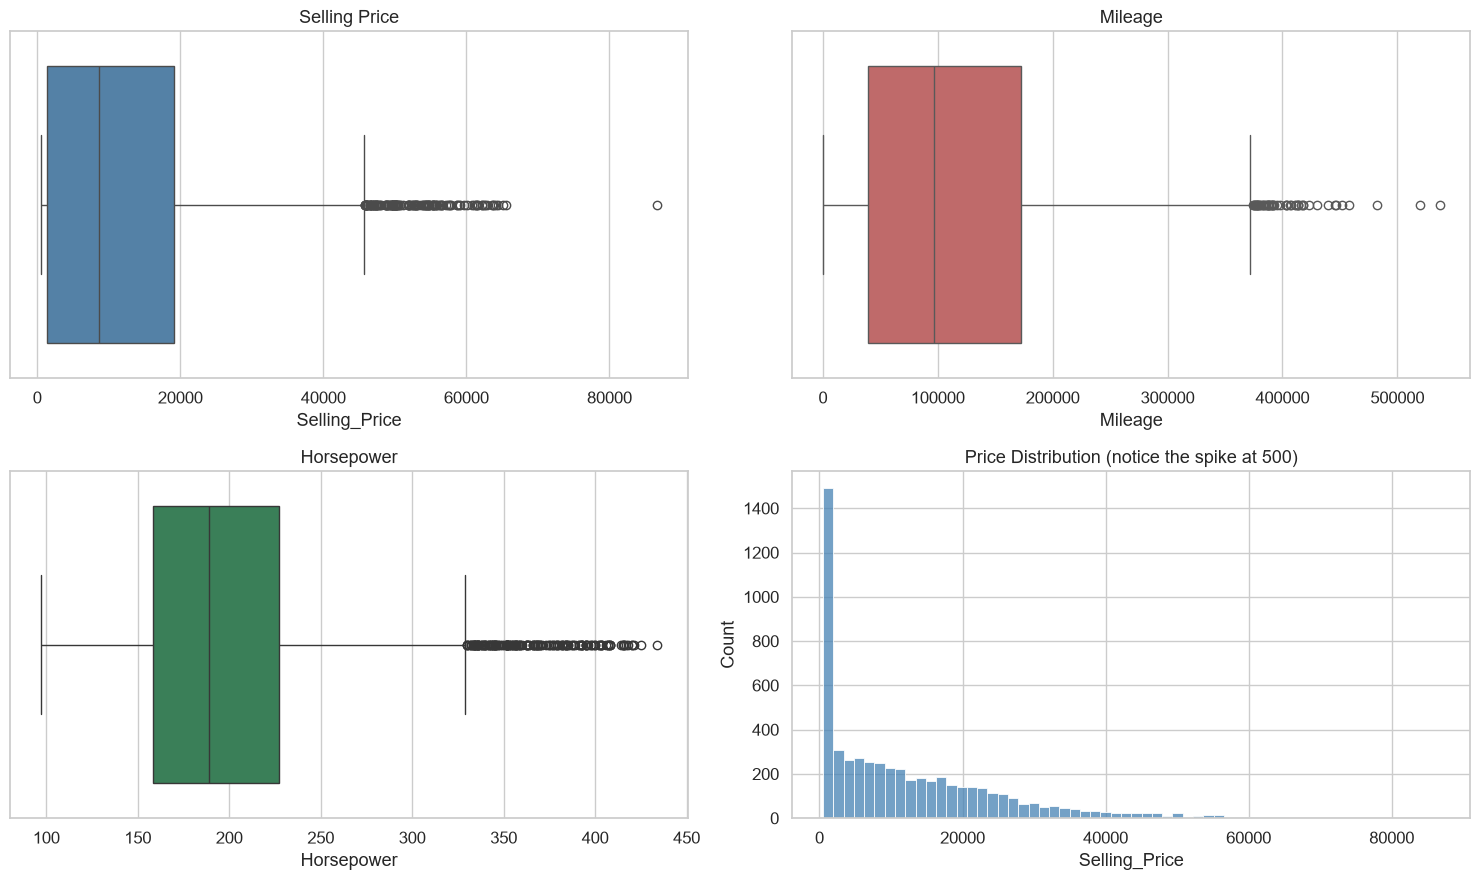

Cars priced exactly 500: 1216
Share: 22.1 %


In [32]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))

sns.boxplot(x=df_clean["Selling_Price"], ax=ax[0, 0], color="steelblue")
ax[0, 0].set_title("Selling Price")

sns.boxplot(x=df_clean["Mileage"], ax=ax[0, 1], color="indianred")
ax[0, 1].set_title("Mileage")

sns.boxplot(x=df_clean["Horsepower"], ax=ax[1, 0], color="seagreen")
ax[1, 0].set_title("Horsepower")

sns.histplot(df_clean["Selling_Price"], bins=60, ax=ax[1, 1], color="steelblue")
ax[1, 1].set_title("Price Distribution (notice the spike at 500)")

plt.tight_layout()
plt.show()

print("Cars priced exactly 500:", (df_clean["Selling_Price"] == 500).sum())
print("Share:", round((df_clean["Selling_Price"] == 500).mean() * 100, 1), "%")

In [33]:
df_clean["Price_Floor"] = (df_clean["Selling_Price"] == 500).astype(int)

# Who are the floor-priced cars?
df_clean.groupby("Price_Floor")[["Year", "Mileage", "Owners"]].mean().round(0)

,Year,Mileage,Owners
Price_Floor,,,
0,2016.0,79446.0,2.0
1,2008.0,238129.0,4.0


In [34]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   Make              5500 non-null   str     
 1   Model             5500 non-null   str     
 2   Year              5500 non-null   int64   
 3   Fuel_Type         5500 non-null   str     
 4   Transmission      5500 non-null   str     
 5   Engine_Size       5500 non-null   float64 
 6   Mileage           5500 non-null   int64   
 7   Horsepower        5500 non-null   float64 
 8   Torque            5500 non-null   float64 
 9   Owners            5500 non-null   int64   
 10  Accident_History  5500 non-null   str     
 11  Service_History   5500 non-null   str     
 12  Color             5500 non-null   str     
 13  Body_Type         5500 non-null   str     
 14  Drivetrain        5500 non-null   str     
 15  Fuel_Efficiency   5500 non-null   float64 
 16  Location          5500 non-null   s

## ✅ Phase 2 Summary

- All missing values handled with **zero rows removed**.
- Specs imputed by **median per Model + Fuel_Type** (more accurate than a global median).
- `Accident_History` unknown kept as its own category, not assumed to be "No".
- **22% of cars sit at a price floor of $500** (old, high-mileage cars) → flagged with `Price_Floor`.
- Outliers reviewed and **kept**: extreme mileage and electric-car efficiency values are real, not errors.

# 📊 Phase 3: Exploratory Data Analysis (EDA)

Price Distribution

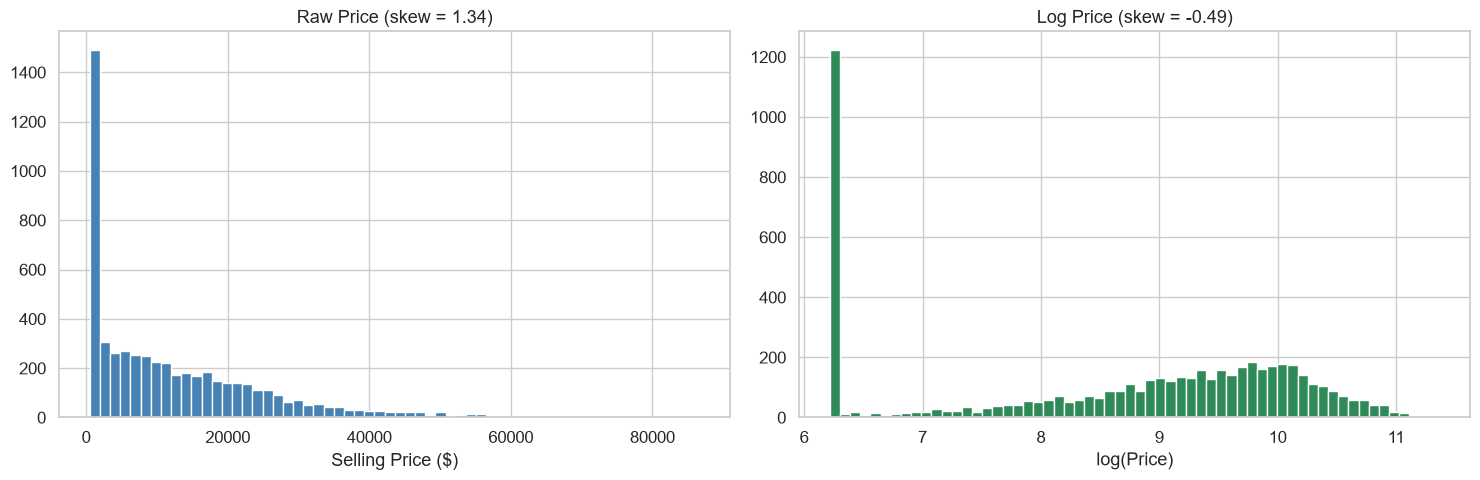

In [35]:
# New features we need for EDA
df_clean["Age"] = 2026 - df_clean["Year"]
df_clean["Log_Price"] = np.log1p(df_clean["Selling_Price"])

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].hist(df_clean["Selling_Price"], bins=60, color="steelblue", edgecolor="white")
ax[0].set_title(f"Raw Price (skew = {df_clean['Selling_Price'].skew():.2f})")
ax[0].set_xlabel("Selling Price ($)")

ax[1].hist(df_clean["Log_Price"], bins=60, color="seagreen", edgecolor="white")
ax[1].set_title(f"Log Price (skew = {df_clean['Log_Price'].skew():.2f})")
ax[1].set_xlabel("log(Price)")

plt.tight_layout()
plt.show()

### 1. Price distribution
- `Selling_Price` is **right-skewed** (skew = 1.34): many affordable cars and a small number of expensive ones.
- After a log transform the skew drops to **-0.49**, so `Log_Price` will be used for modeling.
- A visible spike at **$500** reveals a **price floor** affecting ~22% of cars.

Price Distribution According Brand (Make) & Fuel Type

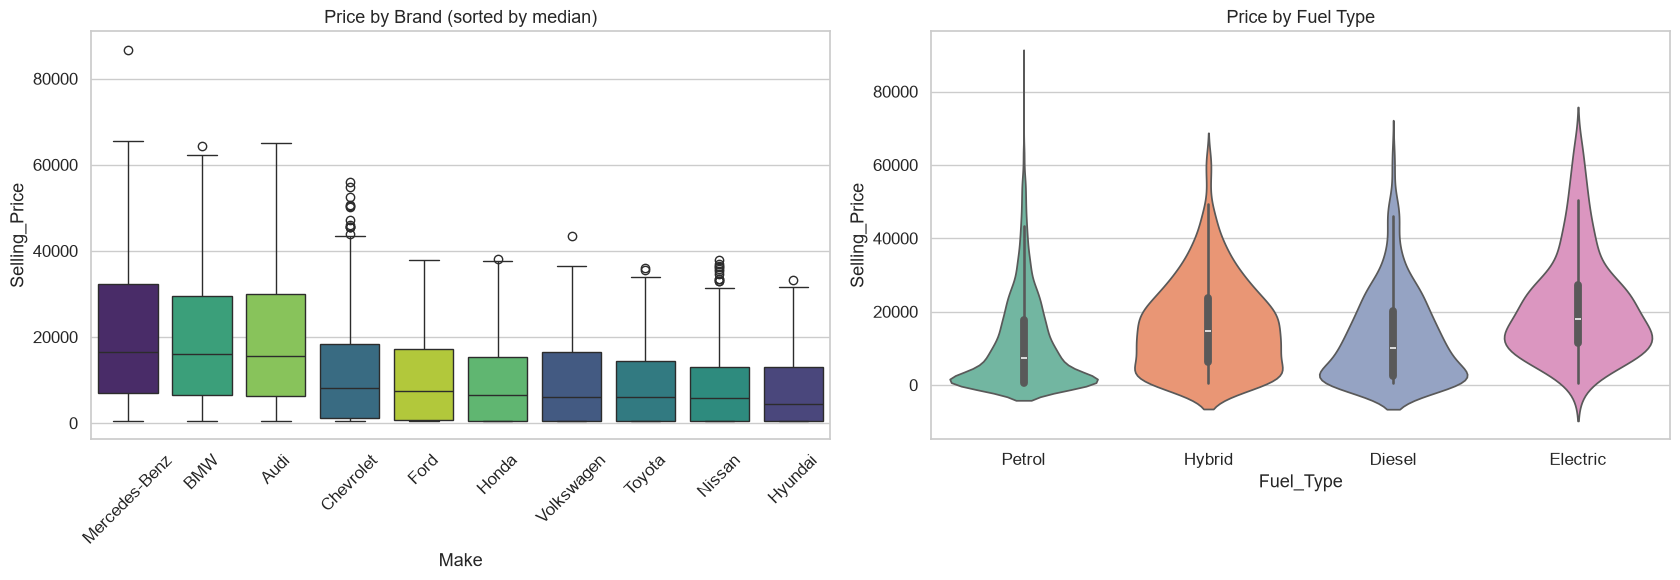

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6))

order = df_clean.groupby("Make")["Selling_Price"].median().sort_values(ascending=False).index
sns.boxplot(data=df_clean, x="Make", y="Selling_Price", order=order,
            hue="Make", palette="viridis", legend=False, ax=ax[0])
ax[0].set_title("Price by Brand (sorted by median)")
ax[0].tick_params(axis="x", rotation=45)

sns.violinplot(data=df_clean, x="Fuel_Type", y="Selling_Price",
               hue="Fuel_Type", palette="Set2", legend=False, ax=ax[1])
ax[1].set_title("Price by Fuel Type")

plt.tight_layout()
plt.show()

### 2. Brand creates a clear price tier
- **Luxury brands** lead: Mercedes-Benz ($16,575), BMW ($15,940), Audi ($15,556).
- All other brands have a median **below $8,200**, with Hyundai the lowest at **$4,359**.

### 3. Fuel type: electric and hybrid cost more, partly because they are newer
- Median price: Electric **$17,866**, Hybrid **$14,590**, Diesel **$10,194**, Petrol **$7,370**.
- But average age differs too: Electric **6.5** years vs Petrol **12.1**, so part of the premium comes from age, not fuel type alone.


Correlation Between Variables

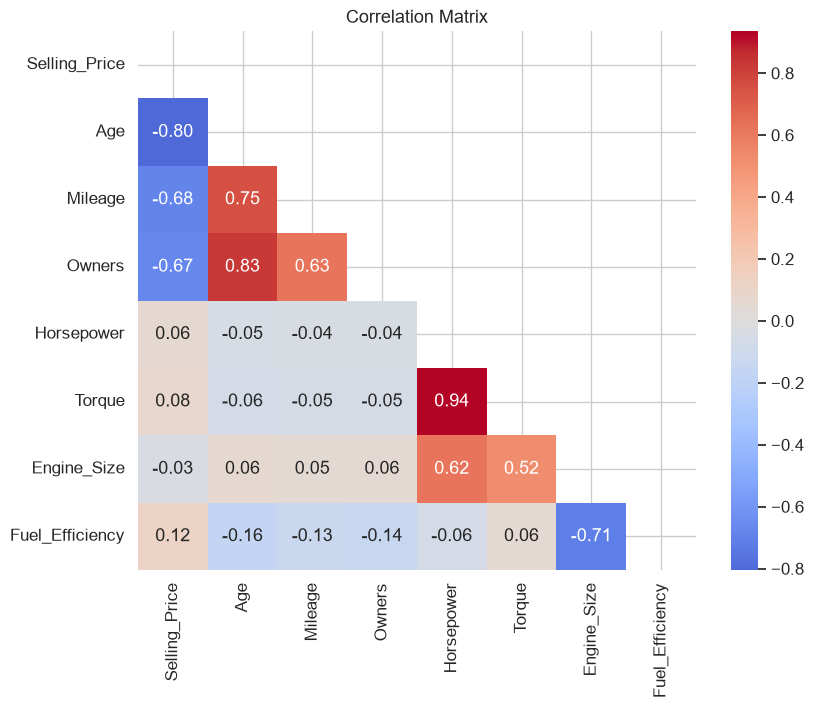

In [37]:
num_cols = ["Selling_Price", "Age", "Mileage", "Owners",
            "Horsepower", "Torque", "Engine_Size", "Fuel_Efficiency"]

plt.figure(figsize=(9, 7))
corr = df_clean[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

Price Distribution vs Age

In [38]:
fig = px.scatter(
    df_clean, x="Age", y="Selling_Price", color="Fuel_Type",
    hover_data=["Make", "Model", "Mileage", "Owners"],
    opacity=0.6, title="Price vs Age (hover to inspect any car)"
)
fig.show()

### 4. Age is the strongest price driver
- Correlation between `Age` and price is **-0.80**, the strongest in the dataset.
- Cars lose roughly **14% of their value per year** (excluding floor-priced cars).
- Median price by age: **$28,840** (0-3 years) → **$13,143** (6-10 years) → **$5,774** (10-15 years) → **$500** (15+ years).


Price Distribution vs Accident Effect

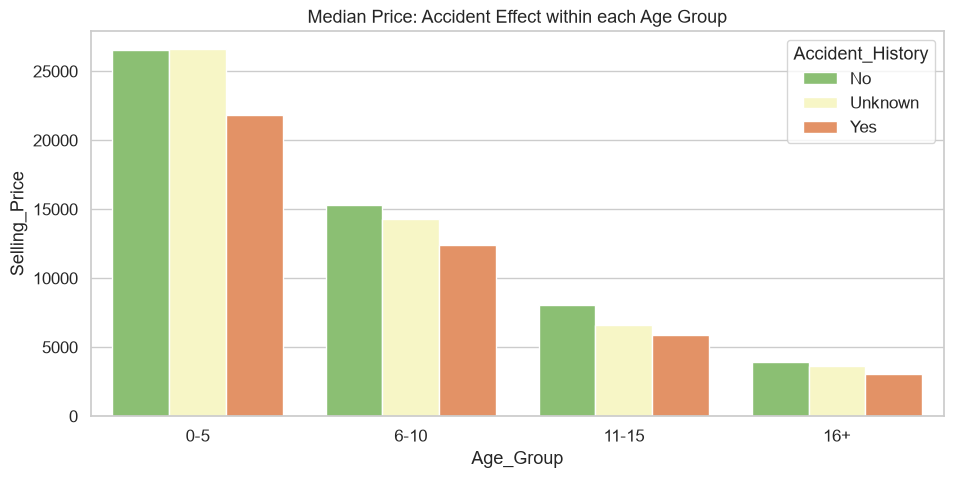

In [39]:
df_clean["Age_Group"] = pd.cut(df_clean["Age"], [0, 5, 10, 15, 22],
                               labels=["0-5", "6-10", "11-15", "16+"])

plt.figure(figsize=(11, 5))
sns.barplot(data=df_clean[df_clean["Price_Floor"] == 0],
            x="Age_Group", y="Selling_Price", hue="Accident_History",
            estimator="median", errorbar=None,
            hue_order=["No", "Unknown", "Yes"], palette="RdYlGn_r")
plt.title("Median Price: Accident Effect within each Age Group")
plt.show()

Accident VS Age 

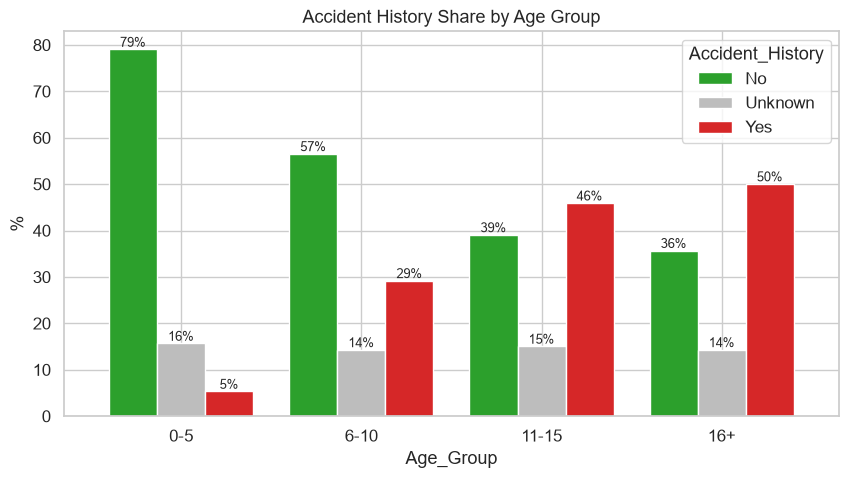

In [40]:
share = (pd.crosstab(df_clean["Age_Group"], df_clean["Accident_History"],
                     normalize="index") * 100)[["No", "Unknown", "Yes"]]

ax = share.plot(kind="bar", figsize=(10, 5),
                color=["#2ca02c", "#bdbdbd", "#d62728"], width=0.8)
ax.set_title("Accident History Share by Age Group")
ax.set_ylabel("%")
plt.xticks(rotation=0)

for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", fontsize=9)

plt.show()

###  Accident history: the real penalty is ~18-26% 
- A naive comparison shows a huge gap ($14,119 vs $3,481) but it is **confounded by age**: the share of cars with accidents grows from **5%** (0-5 years) to **50%** (16+ years).
- Comparing **within the same age group** (excluding floor-priced cars) shows the real accident penalty: **17.7%** (0-5 yrs), **19.2%** (6-10), **26.3%** (11-15), **23.5%** (16+).
- Cars with **unknown** accident history are priced between the two groups.

In [41]:
nf = df_clean[df_clean["Price_Floor"] == 0]   # exclude floor-priced cars

tbl = (nf.groupby(["Age_Group", "Accident_History"], observed=True)["Selling_Price"]
         .median().unstack())
tbl["Penalty_%"] = ((tbl["No"] - tbl["Yes"]) / tbl["No"] * 100).round(1)
tbl

Accident_History,No,Unknown,Yes,Penalty_%
Age_Group,,,,
0-5,26505.0,26580.0,21826.0,17.7
6-10,15334.5,14320.0,12387.0,19.2
11-15,8020.0,6614.0,5907.0,26.3
16+,3959.0,3603.0,3027.0,23.5


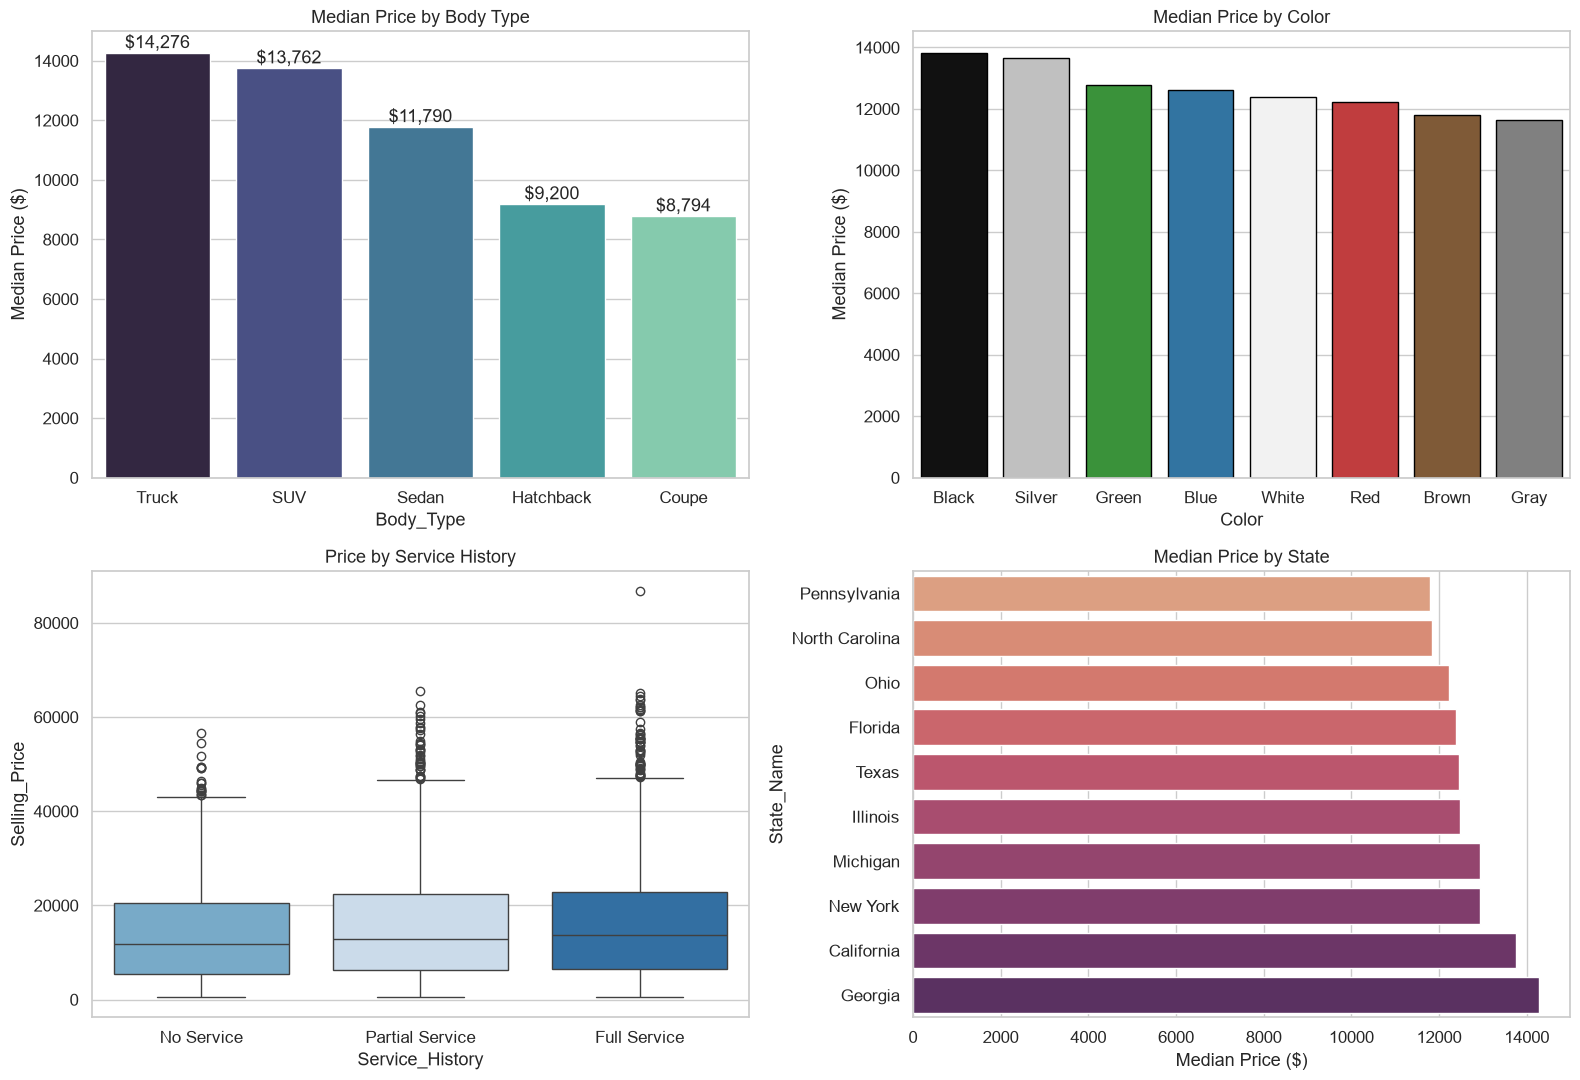

In [42]:
fig, ax = plt.subplots(2, 2, figsize=(16, 11))

# 1) Body type
body = nf.groupby("Body_Type")["Selling_Price"].median().sort_values(ascending=False)
sns.barplot(x=body.index, y=body.values, hue=body.index, palette="mako",
            legend=False, ax=ax[0, 0])
ax[0, 0].set_title("Median Price by Body Type")
ax[0, 0].set_ylabel("Median Price ($)")
for i, v in enumerate(body.values):
    ax[0, 0].text(i, v + 150, f"${v:,.0f}", ha="center")

# 2) Color (bars painted in the real car colors)
col = (nf[nf["Color"] != "Unknown"].groupby("Color")["Selling_Price"]
         .median().sort_values(ascending=False))
car_colors = {"Black": "#111111", "Gray": "#808080", "Silver": "#c0c0c0",
              "White": "#f2f2f2", "Blue": "#1f77b4", "Red": "#d62728",
              "Green": "#2ca02c", "Brown": "#8b5a2b"}
sns.barplot(x=col.index, y=col.values, hue=col.index, palette=car_colors,
            legend=False, edgecolor="black", ax=ax[0, 1])
ax[0, 1].set_title("Median Price by Color")
ax[0, 1].set_ylabel("Median Price ($)")

# 3) Service history
sv = nf[nf["Service_History"] != "Unknown"]
sns.boxplot(data=sv, x="Service_History", y="Selling_Price",
            order=["No Service", "Partial Service", "Full Service"],
            hue="Service_History", palette="Blues", legend=False, ax=ax[1, 0])
ax[1, 0].set_title("Price by Service History")

# 4) State
loc = (nf[nf["State_Name"] != "Unknown"].groupby("State_Name")["Selling_Price"]
         .median().sort_values())
sns.barplot(x=loc.values, y=loc.index, hue=loc.index, palette="flare",
            legend=False, ax=ax[1, 1])
ax[1, 1].set_title("Median Price by State")
ax[1, 1].set_xlabel("Median Price ($)")

plt.tight_layout()
plt.show()

In [43]:
state_price = (nf[nf["Location"] != "Unknown"]
               .groupby(["Location", "State_Name"])["Selling_Price"]
               .median().reset_index())

fig = px.choropleth(state_price, locations="Location", locationmode="USA-states",
                    color="Selling_Price", hover_name="State_Name", scope="usa",
                    color_continuous_scale="Viridis",
                    title="Median Price by State")
fig.show()

## ✅ Phase 3 Summary: Key Insights (Part 1)

### 1. Price distribution
- `Selling_Price` is **right-skewed** (skew = 1.34): many affordable cars and a small number of expensive ones.
- After a log transform the skew drops to **-0.49**, so `Log_Price` will be used for modeling.
- A visible spike at **$500** reveals a **price floor** affecting ~22% of cars.

### 2. Age is the strongest price driver
- Correlation between `Age` and price is **-0.80**, the strongest in the dataset.
- Cars lose roughly **14% of their value per year** (excluding floor-priced cars).
- Median price by age: **$28,840** (0-3 years) → **$13,143** (6-10 years) → **$5,774** (10-15 years) → **$500** (15+ years).

### 3. Ownership history matters a lot
- Median price drops from **$22,846** (1 owner) to **$10,764** (2 owners), more than half the value after the first resale.
- With 5 owners, the median falls to **$3,343**.
- `Mileage` (-0.68) and `Owners` (-0.67) follow `Age` in strength.

### 4. Brand creates a clear price tier
- **Luxury brands** lead: Mercedes-Benz ($16,575), BMW ($15,940), Audi ($15,556).
- All other brands have a median **below $8,200**, with Hyundai the lowest at **$4,359**.

### 5. Fuel type: electric and hybrid cost more, partly because they are newer
- Median price: Electric **$17,866**, Hybrid **$14,590**, Diesel **$10,194**, Petrol **$7,370**.
- But average age differs too: Electric **6.5** years vs Petrol **12.1**, so part of the premium comes from age, not fuel type alone.

### 6. Accident history: the real penalty is ~18-26%, not 75%
- A naive comparison shows a huge gap ($14,119 vs $3,481) but it is **confounded by age**: the share of cars with accidents grows from **5%** (0-5 years) to **50%** (16+ years).
- Comparing **within the same age group** (excluding floor-priced cars) shows the real accident penalty: **17.7%** (0-5 yrs), **19.2%** (6-10), **26.3%** (11-15), **23.5%** (16+).
- Cars with **unknown** accident history are priced between the two groups.


### 7. Engine power barely affects price
- `Horsepower` (0.06), `Torque` (0.08), and `Engine_Size` (-0.03) show almost no correlation with price.
- Condition and history (age, mileage, owners) matter far more than performance specs in this market.

### 8. Body type (excluding floor-priced cars)
- Trucks (**$14,276**) and SUVs (**$13,762**) lead, followed by sedans (**$11,790**), hatchbacks (**$9,200**) and coupes (**$8,794**).


### 9. Service history matters; color and state do not
- **Service history** has a real effect (p = 0.007): full service cars sell for ~$2,000 more than cars with no service record, even within the same age group.
- **Color** (p = 0.16) and **state** (p = 0.44) show differences of ~$2,200 and ~$2,500 in medians, but these are **not statistically significant** and may be random noise.

### 🔑 Takeaway
> Used car prices are driven mainly by **how old the car is, how far it has been driven, and how many owners it has had**. Brand tier comes next, while engine power, color, and location play minor roles.

# 📊 Phase 3 : EDA Part 2

Treemap For Make & Model

In [44]:
tm = (df_clean.groupby(["Make", "Model"])
      .agg(Count=("Selling_Price", "size"),
           Median_Price=("Selling_Price", "median"))
      .reset_index())

fig = px.treemap(tm, path=["Make", "Model"], values="Count",
                 color="Median_Price", color_continuous_scale="Viridis",
                 title="Market Structure: size = number of cars, color = median price")
fig.show()

Parallel Coordinates

In [45]:
pc = df_clean.sample(1500, random_state=42)

fig = px.parallel_coordinates(
    pc, dimensions=["Age", "Mileage", "Owners", "Horsepower", "Selling_Price"],
    color="Selling_Price", color_continuous_scale=px.colors.sequential.Viridis,
    title="Each line is one car (drag on any axis to filter)")
fig.show()

Do electric and hybrid cars hold their value?


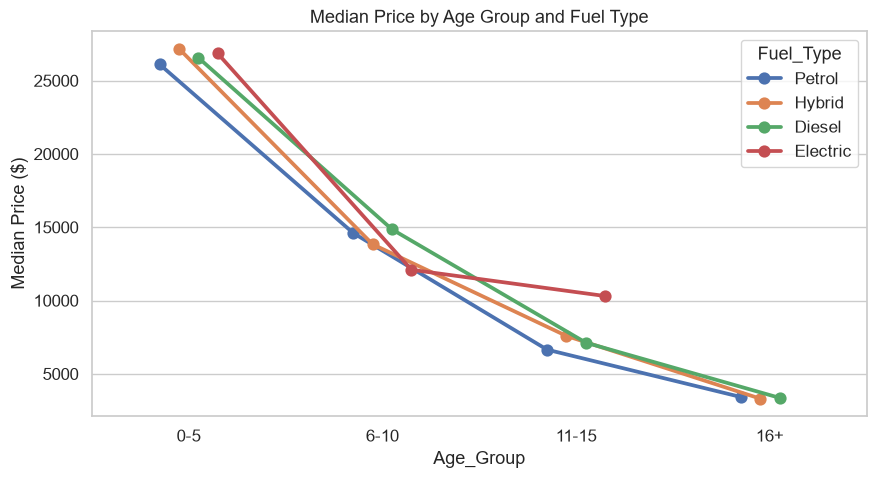

Fuel_Type,Diesel,Electric,Hybrid,Petrol
Age_Group,,,,
0-5,26563.0,26852.0,27180.0,26111.0
6-10,14851.0,12097.0,13833.0,14599.0
11-15,7128.0,10306.0,7586.0,6650.0
16+,3363.0,NaN,3309.0,3421.0


In [46]:
nf = df_clean[df_clean["Price_Floor"] == 0]

plt.figure(figsize=(10, 5))
sns.pointplot(data=nf, x="Age_Group", y="Selling_Price", hue="Fuel_Type",
              estimator="median", errorbar=None, dodge=0.3)
plt.title("Median Price by Age Group and Fuel Type")
plt.ylabel("Median Price ($)")
plt.show()

nf.groupby(["Age_Group", "Fuel_Type"], observed=True)["Selling_Price"].median().unstack().round()

### Electric and Hybrid cars do NOT hold their value better
- Their higher overall median price is explained by age: they are newer.
- Within the same age group, prices are nearly identical across fuel types (e.g. 0-5 years: Electric $26,852, Hybrid $27,180, Petrol $26,111).
- Caution: Electric cars are few (145), with only 19 in the 11-15 year group and none in 16+.


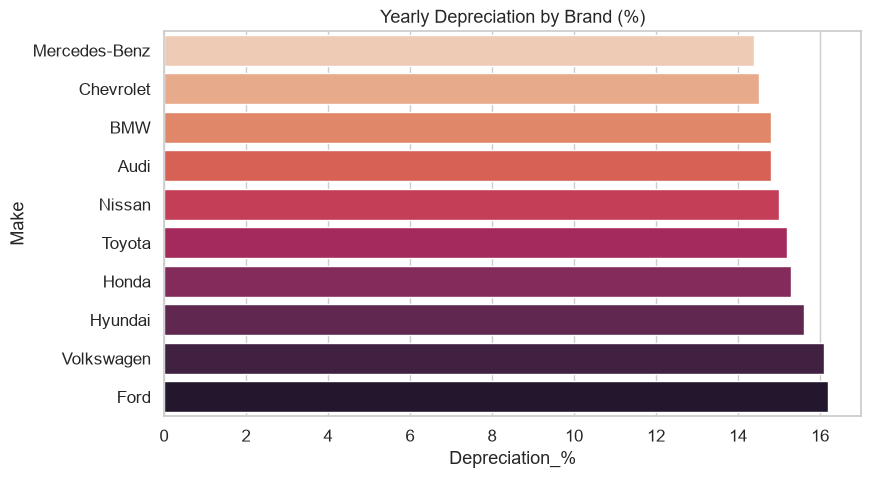

,Make,Depreciation_%
6,Mercedes-Benz,14.4
2,Chevrolet,14.5
1,BMW,14.8
0,Audi,14.8
7,Nissan,15.0
8,Toyota,15.2
4,Honda,15.3
5,Hyundai,15.6
9,Volkswagen,16.1
3,Ford,16.2


In [47]:
rows = []
for make, g in nf.groupby("Make"):
    slope = np.polyfit(g["Age"], np.log(g["Selling_Price"]), 1)[0]
    rows.append((make, round((1 - np.exp(slope)) * 100, 1)))

dep = pd.DataFrame(rows, columns=["Make", "Depreciation_%"]).sort_values("Depreciation_%")

plt.figure(figsize=(9, 5))
sns.barplot(data=dep, x="Depreciation_%", y="Make", hue="Make",
            palette="rocket_r", legend=False)
plt.title("Yearly Depreciation by Brand (%)")
plt.show()
dep

### Depreciation is similar across brands
- Every brand loses between **14.4% and 16.2%** of its value per year.
- Mercedes-Benz (14.4%) and Chevrolet (14.5%) hold value best; Ford (16.2%) and Volkswagen (16.1%) lose it fastest.
- The gap is small: **age matters far more than brand** for depreciation.


# Phase 4: Feature Engineering

New Columns

In [48]:
# Age and Log_Price were created earlier; here we add the rest
df_clean["Mileage_per_Year"] = df_clean["Mileage"] / df_clean["Age"].clip(lower=1)

luxury_brands = ["Mercedes-Benz", "BMW", "Audi"]
df_clean["Is_Luxury"] = df_clean["Make"].isin(luxury_brands).astype(int)

df_clean[["Age", "Mileage", "Mileage_per_Year", "Is_Luxury"]].head()

,Age,Mileage,Mileage_per_Year,Is_Luxury
0,2,100,50.000000,1
1,18,387035,21501.944444,0
2,5,46054,9210.800000,0
3,21,141302,6728.666667,0
4,4,32813,8203.250000,0


In [49]:
cols = ["Selling_Price", "Log_Price", "Age", "Mileage",
        "Mileage_per_Year", "Owners", "Is_Luxury"]
df_clean[cols].corr()[["Selling_Price", "Log_Price"]].round(2)

,Selling_Price,Log_Price
Selling_Price,1.00,0.84
Log_Price,0.84,1.00
Age,-0.80,-0.85
Mileage,-0.68,-0.83
Mileage_per_Year,-0.50,-0.55
Owners,-0.67,-0.72
Is_Luxury,0.38,0.30


## ✅ Phase 4 Summary

- Created `Mileage_per_Year` (usage intensity) and `Is_Luxury` (Mercedes-Benz, BMW, Audi).
- Luxury cars have a median price of **$16,175** vs **$6,250** for the rest.
- Correlations with `Log_Price` are stronger than with raw price (e.g. Mileage: -0.83 vs -0.68), confirming that the log transform was the right choice.
- `Mileage_per_Year` is weaker than `Mileage` alone (-0.50), but adds complementary information about usage.

In [50]:
save_path = r"D:\Codex Ai Course\Codex Training Projects\Python Project\cleaned_cars.csv"
df_clean.to_csv(save_path, index=False)
print("Saved:", df_clean.shape)

Saved: (5500, 25)
